# 03 - Ensembles, tuning and final evaluation
**Milestone 4.** Leads: Ajwan (models and tuning), Ghaleh (evaluation and error analysis).

Order of work: (1) compare ensembles with CV on training data, (2) tune the best one on training data, (3) check bias-variance, (4) evaluate **once** on the test set, (5) analyse errors. After step 4 nothing is changed.

In [1]:
# Setup: make the project root importable (works in Jupyter and in Colab
# after `%cd <repo>/notebooks`).
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.utils import *
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

def save(fig, name):
    """Save a figure to report/figures so it can go straight into the report."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160)
    plt.show()

In [2]:
import json
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, validation_curve

train, test = load_split()
X, y = xy(train)

## 1. Ensembles vs earlier models (training CV only)

In [3]:
ensembles = {
    "Random Forest":     pipeline(RandomForestRegressor(n_estimators=200, n_jobs=1,
                                                         random_state=SEED), kind="tree"),
    "Gradient Boosting": pipeline(GradientBoostingRegressor(random_state=SEED), kind="tree"),
}
ens = pd.DataFrame([cv_scores(name, m, X, y) for name, m in ensembles.items()])
ens.to_csv(RESULTS / "ensemble_results.csv", index=False)

core = pd.read_csv(RESULTS / "core_model_results.csv")   # produced by notebook 02
all_models = pd.concat([core, ens], ignore_index=True).sort_values("val_RMSE_mean")
all_models.to_csv(RESULTS / "all_model_results.csv", index=False)
all_models[["Model", "val_RMSE_mean", "val_RMSE_std", "val_MAE_mean", "val_R2_mean",
            "train_RMSE_mean", "train_R2_mean"]]

,Model,val_RMSE_mean,val_RMSE_std,val_MAE_mean,val_R2_mean,train_RMSE_mean,train_R2_mean
6,Random Forest,79.445,19.328,51.860,0.743,11.475,0.991
7,Gradient Boosting,89.591,18.443,62.746,0.683,44.359,0.871
5,Decision Tree,95.433,21.538,62.041,0.642,0.165,1.000
1,Linear Regression,109.046,19.532,80.592,0.542,68.964,0.684
3,Ridge (alpha=1),109.117,19.597,80.681,0.542,68.966,0.684
2,Linear Regression (log y),113.527,30.754,76.504,0.511,65.206,0.715
4,k-NN (k=10),132.771,28.460,99.110,0.333,70.630,0.659
0,Mean baseline,180.623,42.739,138.158,-0.214,122.965,0.000


| Ensemble | Why suitable | Weakness |
|---|---|---|
| Random Forest (bagging) | Averages many deep trees -> keeps the tree's flexibility but lowers its variance | Larger and slower; cannot predict outside the range of training targets (growth trend) |
| Gradient Boosting | Adds shallow trees that correct previous errors -> lowers bias step by step | More hyperparameters; can overfit with too many/deep trees |

## 2. Hyperparameter tuning of the best ensemble (training data only)

In [4]:
best_name = ens.sort_values("val_RMSE_mean").iloc[0]["Model"]
print("Selected for tuning:", best_name)

grids = {
    "Random Forest":     {"model__n_estimators": [200, 400],
                          "model__max_depth": [15, None],
                          "model__min_samples_leaf": [1, 3]},
    "Gradient Boosting": {"model__n_estimators": [200, 400],
                          "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [3, 5]},
}
search = GridSearchCV(ensembles[best_name], grids[best_name], cv=time_cv(),
                      scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
search.fit(X, y)

tuning = pd.DataFrame(search.cv_results_)
tuning["val_RMSE"] = -tuning["mean_test_score"]
tuning["train_RMSE"] = -tuning["mean_train_score"]
tuning.to_csv(RESULTS / "tuning_results.csv", index=False)
print("Best parameters:", search.best_params_)
print("Best CV RMSE: %.1f (untuned: %.1f)" % (-search.best_score_,
      ens.set_index("Model").loc[best_name, "val_RMSE_mean"]))
tuning.sort_values("val_RMSE")[["params", "val_RMSE", "std_test_score", "train_RMSE"]].head(8)

Selected for tuning: Random Forest
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV RMSE: 79.4 (untuned: 79.4)


,params,val_RMSE,std_test_score,train_RMSE
4,"{'model__max_depth': None, 'model__min_samples...",79.445,19.328,11.475
5,"{'model__max_depth': None, 'model__min_samples...",79.505,19.492,11.443
0,"{'model__max_depth': 15, 'model__min_samples_l...",79.609,19.362,14.743
1,"{'model__max_depth': 15, 'model__min_samples_l...",79.625,19.566,14.718
6,"{'model__max_depth': None, 'model__min_samples...",81.135,20.381,19.956
7,"{'model__max_depth': None, 'model__min_samples...",81.162,20.498,19.943
2,"{'model__max_depth': 15, 'model__min_samples_l...",81.270,20.542,20.893
3,"{'model__max_depth': 15, 'model__min_samples_l...",81.296,20.591,20.880


## 3. Bias-variance check: validation curve of a single decision tree
Shallow trees = high bias (both errors high). Deep trees = high variance (training error near zero, validation error rises). Ensembles are a way to escape this trade-off.

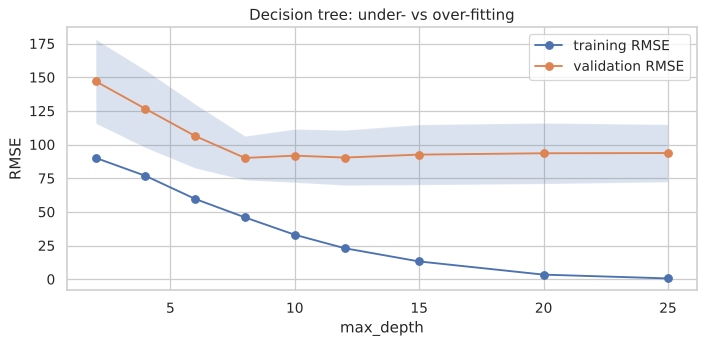

In [5]:
depths = [2, 4, 6, 8, 10, 12, 15, 20, 25]
tr, va = validation_curve(pipeline(DecisionTreeRegressor(random_state=SEED), kind="tree"), X, y,
                          param_name="model__max_depth", param_range=depths, cv=time_cv(),
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, -tr.mean(1), "o-", label="training RMSE")
ax.plot(depths, -va.mean(1), "o-", label="validation RMSE")
ax.fill_between(depths, -va.mean(1) - va.std(1), -va.mean(1) + va.std(1), alpha=.2)
ax.set(xlabel="max_depth", ylabel="RMSE", title="Decision tree: under- vs over-fitting")
ax.legend()
save(fig, "fig8_validation_curve.png")

**Interpretation:** at depth 2-6 both errors are high (high bias, under-fitting). Validation RMSE is lowest around depth 8-12 (about 90). Deeper trees push training RMSE towards 0 while validation RMSE stays around 93: the extra depth only memorises noise (high variance, over-fitting). The random forest keeps deep trees but averages 200 of them, which brings validation RMSE down to 79.

## 4. Final evaluation on the test set - run once
The model selected and tuned above is refitted on all training data (GridSearchCV does this automatically) and scored on the untouched test period.

In [6]:
final_model = search.best_estimator_
X_test, y_test = xy(test)
pred_train = final_model.predict(X)
pred_test = final_model.predict(X_test)

summary = {
    "selected_model": best_name,
    "best_params": search.best_params_,
    "train": metrics(y, pred_train),
    "cv": {"RMSE": float(-search.best_score_)},
    "test": metrics(y_test, pred_test),
    "baseline_test": metrics(y_test, np.full(len(y_test), y.mean())),
    "test_period": [str(test["timestamp"].min()), str(test["timestamp"].max())],
}
(RESULTS / "final_metrics.json").write_text(json.dumps(summary, indent=2, default=str))
pd.DataFrame({k: summary[k] for k in ["train", "test", "baseline_test"]}).T

,MAE,RMSE,R2
train,8.650,14.360,0.993
test,45.152,69.900,0.899
baseline_test,174.985,232.608,-0.113


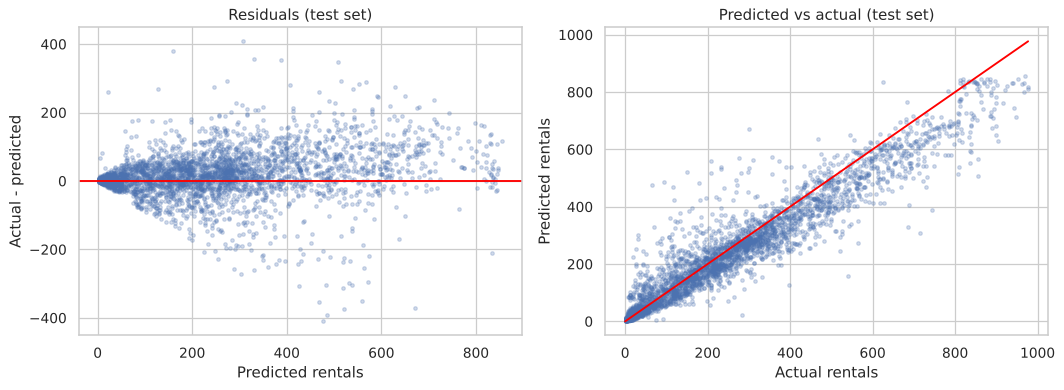

In [7]:
errors = test[["timestamp", "hr", "workingday", "weathersit", "cnt"]].copy()
errors["prediction"] = pred_test
errors["residual"] = errors["cnt"] - errors["prediction"]     # positive = under-prediction
errors["abs_error"] = errors["residual"].abs()
errors.to_csv(RESULTS / "test_predictions.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(errors["prediction"], errors["residual"], alpha=.25, s=8)
ax[0].axhline(0, color="red")
ax[0].set(xlabel="Predicted rentals", ylabel="Actual - predicted", title="Residuals (test set)")
ax[1].scatter(errors["cnt"], errors["prediction"], alpha=.25, s=8)
lim = errors[["cnt", "prediction"]].max().max()
ax[1].plot([0, lim], [0, lim], color="red")
ax[1].set(xlabel="Actual rentals", ylabel="Predicted rentals", title="Predicted vs actual (test set)")
save(fig, "fig9_residuals.png")

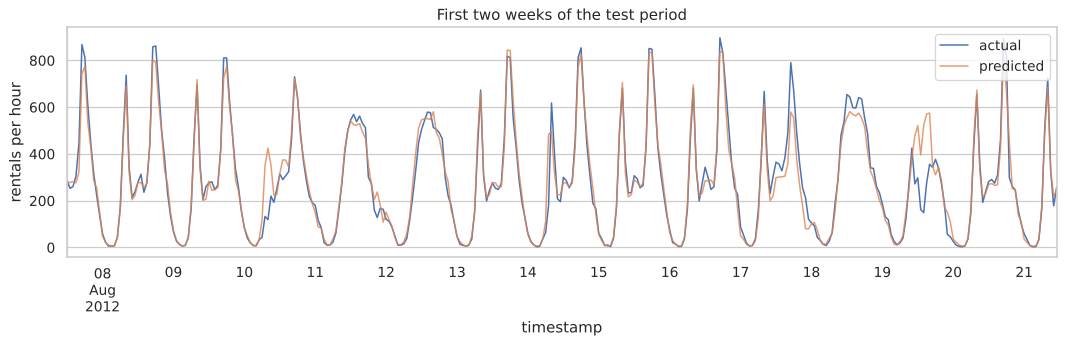

In [8]:
# two weeks of the test period: does the model follow the daily rhythm?
window = errors.set_index("timestamp").iloc[:24 * 14]
fig, ax = plt.subplots(figsize=(12, 4))
window["cnt"].plot(ax=ax, label="actual", lw=1.2)
window["prediction"].plot(ax=ax, label="predicted", lw=1.2, alpha=.8)
ax.set(title="First two weeks of the test period", ylabel="rentals per hour")
ax.legend()
save(fig, "fig10_test_timeline.png")

## 5. Error analysis

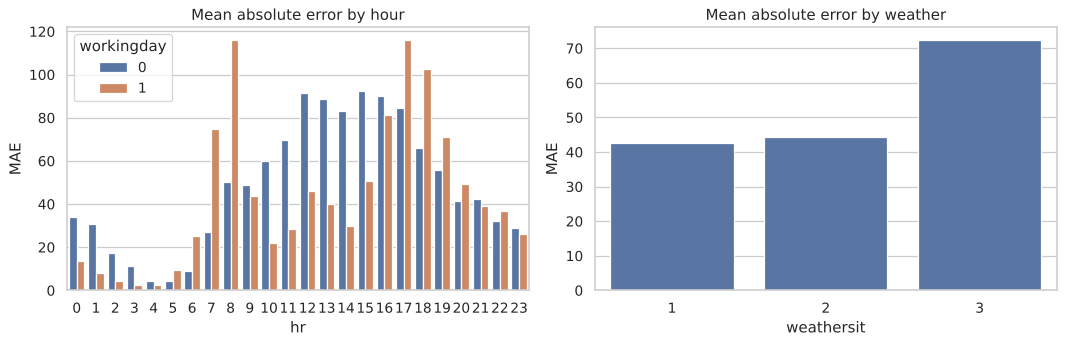

,rows,MAE,mean_residual
weathersit,,,
1,2162,42.486,20.121
2,1076,44.469,14.890
3,238,72.449,-9.200


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=errors, x="hr", y="abs_error", hue="workingday", errorbar=None, ax=ax[0])
ax[0].set(title="Mean absolute error by hour", ylabel="MAE")
sns.barplot(data=errors, x="weathersit", y="abs_error", errorbar=None, ax=ax[1])
ax[1].set(title="Mean absolute error by weather", ylabel="MAE")
save(fig, "fig11_error_groups.png")

by_hour = errors.groupby(["workingday", "hr"])[["abs_error", "residual"]].mean()
by_hour.to_csv(RESULTS / "error_by_hour.csv")
by_weather = errors.groupby("weathersit").agg(rows=("cnt", "size"), MAE=("abs_error", "mean"),
                                              mean_residual=("residual", "mean"))
by_weather.to_csv(RESULTS / "error_by_weather.csv")
by_weather

In [10]:
# the 10 worst predictions - look for holidays, storms or unusual days
worst = errors.sort_values("abs_error", ascending=False).head(10)
worst.to_csv(RESULTS / "worst_predictions.csv", index=False)
worst

,timestamp,hr,workingday,weathersit,cnt,prediction,residual,abs_error
17196,2012-12-24 08:00:00,8,1,1,66,476.275,-410.275,410.275
15252,2012-10-02 17:00:00,17,1,3,715,306.840,408.160,408.160
16454,2012-11-23 08:00:00,8,1,1,94,485.220,-391.220,391.220
16190,2012-11-12 08:00:00,8,0,1,540,159.540,380.460,380.460
14193,2012-08-19 14:00:00,14,0,3,149,521.880,-372.880,372.880
16463,2012-11-23 17:00:00,17,1,2,300,671.440,-371.440,371.440
15253,2012-10-02 18:00:00,18,1,3,687,330.795,356.205,356.205
15470,2012-10-11 19:00:00,19,1,1,743,388.325,354.675,354.675
15890,2012-10-30 19:00:00,19,1,2,115,467.905,-352.905,352.905
16464,2012-11-23 18:00:00,18,1,2,208,558.800,-350.800,350.800


Mean residual on test (positive = model under-predicts): 16.5


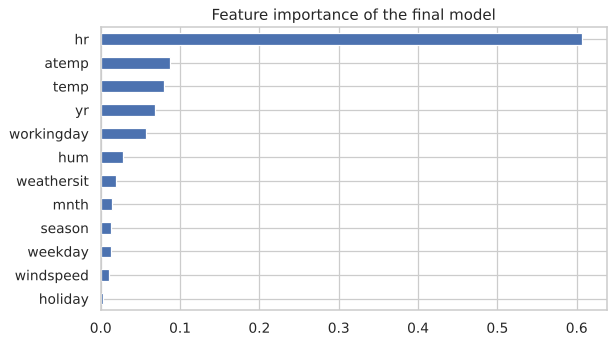

In [11]:
print("Mean residual on test (positive = model under-predicts):", errors["residual"].mean().round(1))

# which inputs the final model relies on (impurity importance, training fit)
importance = pd.Series(final_model.named_steps["model"].feature_importances_,
                       index=NUMERIC + CATEGORICAL).sort_values()
importance.to_csv(RESULTS / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(7, 4))
importance.plot.barh(ax=ax, title="Feature importance of the final model")
save(fig, "fig12_feature_importance.png")

### Discussion
- **Main metric:** RMSE, because large errors at rush hours are the costly ones for planning bikes. MAE (45 bikes/hour on test) shows the typical error and R² the explained variance.
- **Results:** the tuned random forest reached test RMSE 69.9, MAE 45.2 and R² 0.90, compared with RMSE 232.6 for the mean baseline (70% lower). Tuning barely changed the CV score (79.4 with default depth and 200 trees), so the forest was already well configured.
- **Over/under-fitting:** training RMSE is 14.4 against 79.4 in CV and 69.9 on test. The gap shows variance, but the test score is good. The test error is lower than the CV mean because the final model is trained on 19 months of data, while the early CV folds trained on only 3-6 months (fold RMSE 91, 53, 66, 109, 78).
- **Where it fails:** errors are largest at working-day rush hours (MAE about 116 at 08:00 and 17:00) and in light rain/snow (MAE 72). The mean residual is +16.5, so the model under-predicts on average, mostly in September-October 2012 (+24 to +32): demand kept growing beyond what the training data showed, and a forest cannot predict above values it has seen. The worst single errors are special days: Christmas Eve 2012 and the day after Thanksgiving (counted as working days but with few commuters), Hurricane Sandy (30 Oct 2012), and Veterans Day (12 Nov 2012, flagged as a holiday but with normal commuting).
- **Feature importance:** hour dominates (0.61), followed by temperature (`atemp` 0.09, `temp` 0.08), year (0.07) and working day (0.06).
- **Ideas for improvement:** lag features (demand in previous hours/days, built from past data only), a calendar of special days, forecast weather, a time trend or regular retraining, and separate models for `casual` and `registered`.